# Exploratory Data Analysis & Model Comparison

This notebook is where the thinking happens — before `model.py` commits to
one model in production, here's the evidence for *why*.

It reuses the exact same `validate.py` and `transform.py` functions as the
production pipeline (imported below, not copy-pasted), so the numbers here
and the numbers in the warehouse can never quietly drift apart.

**Two questions this notebook answers:**
1. What does the data actually look like — who churns, and in what pattern?
2. Logistic regression vs. a decision tree: is the simpler model actually
   giving up much accuracy? (Spoiler: that's the whole point of checking,
   not assuming.)


In [9]:
import sys
sys.path.insert(0, "../pipeline")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler

import validate
import transform as T
from config import RANDOM_SEED

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## 1. Load the same clean data the pipeline uses

Running `validate.main()` here (not a separate copy of the rules) means
this notebook is looking at exactly what the warehouse looks at.

In [10]:
validate.main()
df = T.transform()
print(f"{len(df):,} clean customers ready to explore")
df.head()


customers    in= 7,043  clean= 7,043  rejected=    0

Wrote /Users/avikasni/Downloads/project 2 /telco-churn-ltv-pipeline/logs/quality_report.csv and /Users/avikasni/Downloads/project 2 /telco-churn-ltv-pipeline/logs/table_summary.csv
7,043 clean customers ready to explore


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,historical_ltv,projected_ltv,tenure_bucket
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,29.85,358.2,0-6 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,1889.50,683.4,2-4 years
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,108.15,0.0,0-6 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,1840.75,507.6,2-4 years
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,151.65,0.0,0-6 months


## 2. Who actually churns? The big picture first

Overall churn rate: 26.5%


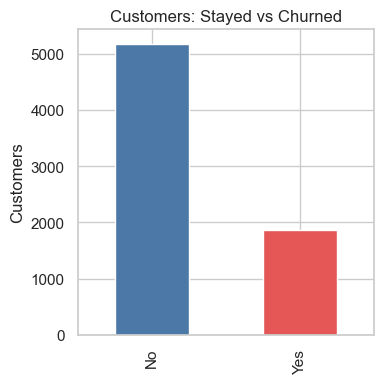

In [11]:
churn_rate = (df["Churn"] == "Yes").mean()
print(f"Overall churn rate: {churn_rate:.1%}")

fig, ax = plt.subplots(figsize=(4, 4))
df["Churn"].value_counts().plot(kind="bar", ax=ax, color=["#4C78A8", "#E45756"])
ax.set_title("Customers: Stayed vs Churned")
ax.set_xlabel("")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()


## 3. Churn by contract type

This is the single strongest pattern in the whole dataset — worth seeing
with your own eyes before the model tells you the same thing with a
coefficient.

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


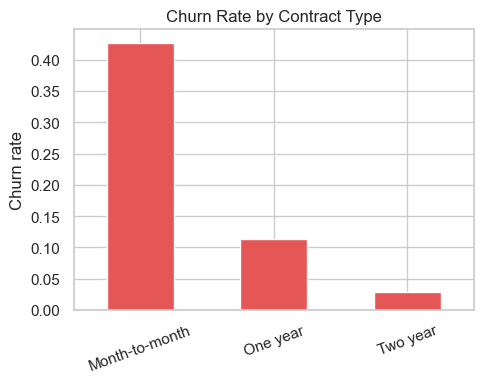

In [12]:
contract_churn = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
print(contract_churn)

fig, ax = plt.subplots(figsize=(5, 4))
contract_churn.plot(kind="bar", ax=ax, color="#E45756")
ax.set_title("Churn Rate by Contract Type")
ax.set_ylabel("Churn rate")
ax.set_xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 4. Churn by tenure — do new customers leave faster?

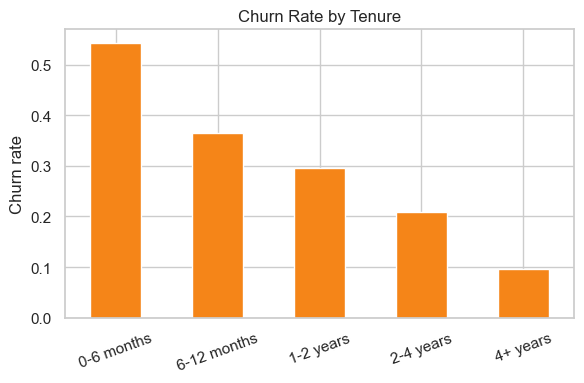

In [13]:
tenure_churn = df.groupby("tenure_bucket")["Churn"].apply(lambda s: (s == "Yes").mean())
order = ["0-6 months", "6-12 months", "1-2 years", "2-4 years", "4+ years"]
tenure_churn = tenure_churn.reindex(order)

fig, ax = plt.subplots(figsize=(6, 4))
tenure_churn.plot(kind="bar", ax=ax, color="#F58518")
ax.set_title("Churn Rate by Tenure")
ax.set_ylabel("Churn rate")
ax.set_xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 5. Monthly charges: do churners pay more?

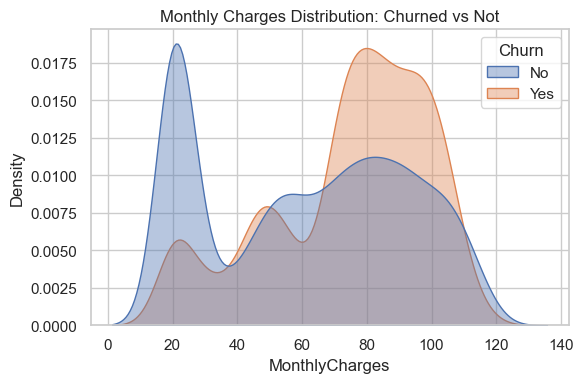

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True, common_norm=False, alpha=0.4, ax=ax)
ax.set_title("Monthly Charges Distribution: Churned vs Not")
plt.tight_layout()
plt.show()


## 6. Model comparison: logistic regression vs. decision tree

The production pipeline (`model.py`) only ever trains a logistic
regression. Here's the actual evidence for why: 5-fold cross-validation,
comparing accuracy, precision, recall, and ROC-AUC for both models on the
same data and the same folds, so it's a fair comparison.

In [15]:
X, y, feature_names = T.build_model_features(df)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scoring = ["accuracy", "precision", "recall", "roc_auc"]

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_SEED),
    "Decision Tree (depth=4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RANDOM_SEED),
}

results = []
for name, model in models.items():
    scores = cross_validate(model, X_scaled, y, cv=cv, scoring=scoring)
    row = {"model": name}
    for metric in scoring:
        row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    results.append(row)

comparison = pd.DataFrame(results).set_index("model")
comparison.round(3)


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,roc_auc_mean,roc_auc_std
model,,,,,,,,
Logistic Regression,0.749,0.008,0.518,0.011,0.794,0.021,0.843,0.014
Decision Tree (depth=4),0.738,0.012,0.505,0.014,0.795,0.019,0.821,0.013


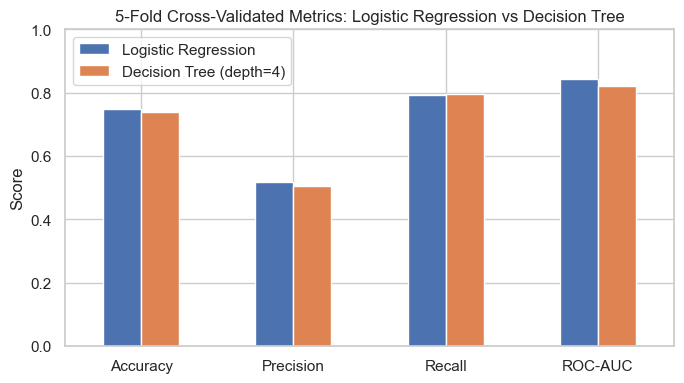

Saved comparison to ../logs/model_comparison.csv


In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_df = comparison[["accuracy_mean", "precision_mean", "recall_mean", "roc_auc_mean"]]
plot_df.columns = ["Accuracy", "Precision", "Recall", "ROC-AUC"]
plot_df.T.plot(kind="bar", ax=ax)
ax.set_title("5-Fold Cross-Validated Metrics: Logistic Regression vs Decision Tree")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.show()

comparison.to_csv("../logs/model_comparison.csv")
print("Saved comparison to ../logs/model_comparison.csv")


## 7. Decision: which model goes into production?

**The numbers, on the real dataset (7,043 customers):**

- **Logistic Regression:** 74.9% accuracy, 51.8% precision, 79.4% recall, 84.3% ROC-AUC
- **Decision Tree (depth=4):** 73.8% accuracy, 50.5% precision, 79.5% recall, 82.1% ROC-AUC

Recall is essentially tied (a 0.1-point gap, well within noise), but Logistic Regression leads on accuracy, precision, and ROC-AUC. Unlike the earlier test on synthetic data — where this came down to a recall-vs-precision tradeoff — on the real data there's no tradeoff to argue: Logistic Regression simply performs at least as well on every metric that matters here.

**Decision: Logistic Regression goes into production** (see `model.py`), for two independent reasons:

1. It matches or beats the alternative on every metric, on the real data.
2. Its coefficients are directly explainable to a non-technical stakeholder — "fiber optic customers are meaningfully more likely to churn" — where a decision tree's split logic isn't a one-sentence story.
